Import Libraries

In [ ]:
import os
import glob
import random

import numpy as np
import pandas as pd
import splitfolders

import cv2  
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping # type: ignore
from tensorflow.keras.preprocessing.image import ImageDataGenerator  # type: ignore
from tensorflow.keras.models import Sequential  # type: ignore
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D  # type: ignore
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint  # type: ignore
from sklearn.metrics import confusion_matrix

from sklearn.metrics import classification_report, confusion_matrix

Read and Load Data

In [30]:
# Define the base directory path
# If the folder is in the same directory as the script, just use its name
base_dir = 'cell_images'

# Define paths for the subdirectories
parasitized_dir = os.path.join(base_dir, 'Parasitized')
uninfected_dir = os.path.join(base_dir, 'Uninfected')

# Get the names of all images inside both folders
parasitized_images = os.listdir(parasitized_dir)
uninfected_images = os.listdir(uninfected_dir)

# Print dataset statistics
print(f"Total Parasitized Images: {len(parasitized_images)}")
print(f"Total Uninfected Images: {len(uninfected_images)}")

# Class Imbalance Check
if len(parasitized_images) == len(uninfected_images):
    print("The dataset is perfectly balanced")
else:
    print("Warning: The dataset is imbalanced.")

Total Parasitized Images: 13779
Total Uninfected Images: 13779
The dataset is perfectly balanced


EDA & Show Images

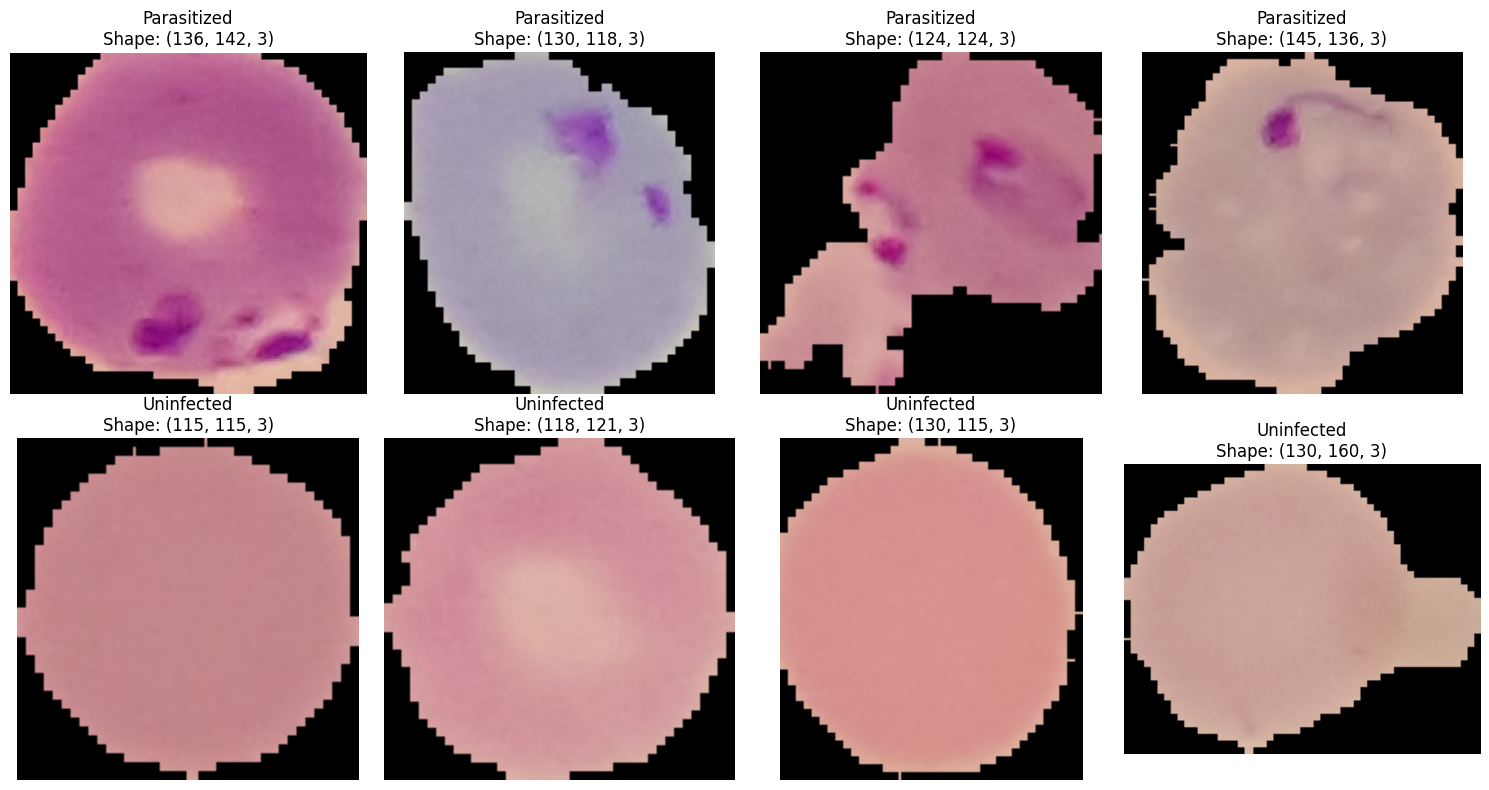

In [31]:
plt.figure(figsize=(15, 8))

# 1. Display 4 random Parasitized images
for i in range(4):
    plt.subplot(2, 4, i+1)
    
    random_image = random.choice(parasitized_images)
    img_path = os.path.join(parasitized_dir, random_image)
    
    img = mpimg.imread(img_path)
    
    plt.imshow(img)
    plt.title(f"Parasitized\nShape: {img.shape}")
    plt.axis('off')

# 2. Display 4 random Uninfected images
for i in range(4):
    plt.subplot(2, 4, i+5)
    
    random_image = random.choice(uninfected_images)
    img_path = os.path.join(uninfected_dir, random_image)
    
    img = mpimg.imread(img_path)
    
    plt.imshow(img)
    plt.title(f"Uninfected\nShape: {img.shape}")
    plt.axis('off')

plt.tight_layout()
plt.show()

Data Cleaning

In [32]:
valid_extensions = ('.png', '.jpg', '.jpeg', '.bmp')
corrupted_files = []

folders_to_check = [parasitized_dir, uninfected_dir]

for folder_path in folders_to_check:
    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)
        
        # 1. Check for valid image extensions
        if not filename.lower().endswith(valid_extensions):
            corrupted_files.append(file_path)
            continue
            
        # 2. Check for empty files (zero bytes)
        if os.path.getsize(file_path) == 0:
            corrupted_files.append(file_path)
            continue
            
        # 3. Check if the image can be opened and is not corrupted
        try:
            img = cv2.imread(file_path)
            if img is None:
                corrupted_files.append(file_path)
        except Exception:
            corrupted_files.append(file_path)

print(f"Total corrupted or invalid files found: {len(corrupted_files)}")

for file in corrupted_files:
    os.remove(file)
    print(f"Removed: {file}")

Total corrupted or invalid files found: 0


Split Data

In [33]:
input_folder = base_dir
output_folder = 'dataset_split'

# Split with a ratio.
splitfolders.ratio(
    input_folder, 
    output=output_folder, 
    seed=42, 
    ratio=(0.7, 0.15, 0.15)
)

print("Data splitting is completed successfully.")

Copying files: 27558 files [00:56, 489.51 files/s]

Data splitting is completed successfully.


Data Preprocessing

In [34]:
# 1. Define new paths after splitting
train_dir = os.path.join(output_folder, 'train')
val_dir = os.path.join(output_folder, 'val')
test_dir = os.path.join(output_folder, 'test')

# 2. Image Hyperparameters
IMG_WIDTH = 130
IMG_HEIGHT = 130
BATCH_SIZE = 32

# 3. Create ImageDataGenerator instances ONLY for preprocessing (Rescaling)
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# 4. Load Data and Apply Resizing
print("Loading Training Data:")
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

print("\nLoading Validation Data:")
val_data = val_datagen.flow_from_directory(
    val_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

print("\nLoading Testing Data:")
test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Loading Training Data:
Found 19290 images belonging to 2 classes.

Loading Validation Data:
Found 4132 images belonging to 2 classes.

Loading Testing Data:
Found 4136 images belonging to 2 classes.


CNN Architecture

In [35]:
# Initialize the CNN model
model = Sequential()

# Add an explicit Input layer to resolve the warning
model.add(tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)))

# 1. First Convolutional Block
model.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# 2. Second Convolutional Block
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# 3. Third Convolutional Block
model.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# 4. Flattening Layer
model.add(Flatten())

# 5. Fully Connected (Dense) Layers
model.add(Dense(units=128, activation='relu'))
# Dropout is temporarily removed to test baseline performance

# 6. Output Layer
model.add(Dense(units=1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Print the model architecture summary
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 62, 62, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 29, 29, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Model Training

In [36]:
# 1. Model Training
EPOCHS = 10

print("Starting Model Training...")
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS
)
print("Training Completed")

Starting Model Training...


c:\Users\ezath\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 386s 633ms/step - accuracy: 0.8414 - loss: 0.3386 - val_accuracy: 0.9364 - val_loss: 0.1822
Epoch 2/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 168s 279ms/step - accuracy: 0.9463 - loss: 0.1612 - val_accuracy: 0.9547 - val_loss: 0.1360
Epoch 3/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 166s 275ms/step - accuracy: 0.9580 - loss: 0.1286 - val_accuracy: 0.9567 - val_loss: 0.1331
Epoch 4/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 161s 268ms/step - accuracy: 0.9622 - loss: 0.1113 - val_accuracy: 0.9504 - val_loss: 0.1510
Epoch 5/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 166s 274ms/step - accuracy: 0.9683 - loss: 0.0921 - val_accuracy: 0.9533 - val_loss: 0.1673
Epoch 6/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 167s 277ms/step - accuracy: 0.9765 - loss: 0.0694 - val_accuracy: 0.9535 - val_loss: 0.1732
Epoch 7/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 166s 275ms/step - accuracy: 0.9834 - loss: 0.0505 - val_accuracy: 0.9533 - val_loss: 0.1831
Epoch 8/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 155s 257ms/step - accuracy: 0.9880 -

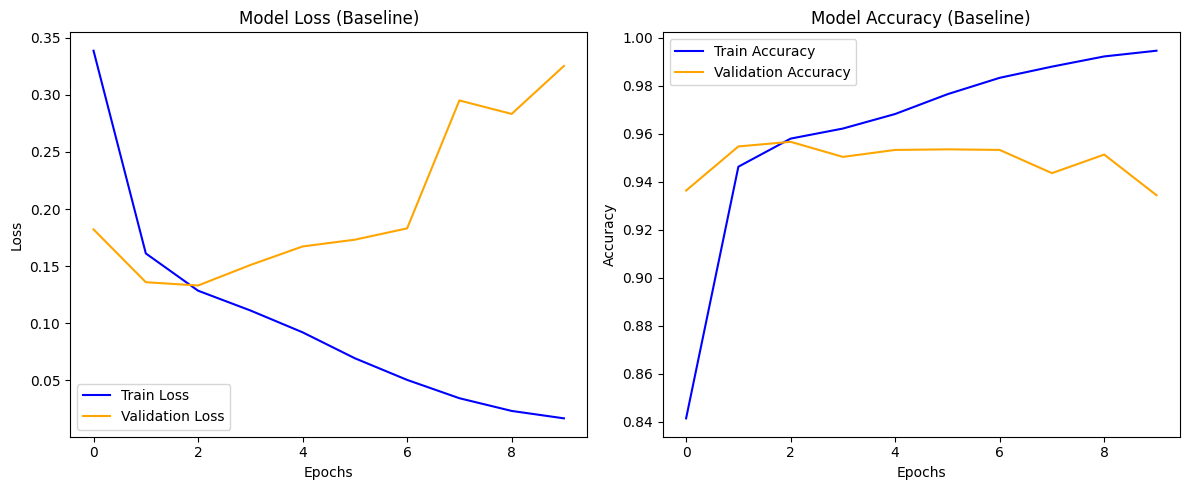

In [37]:
# 2. Plotting the Learning Curves
plt.figure(figsize=(12, 5))

# Plot Model Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Model Loss (Baseline)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot Model Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Model Accuracy (Baseline)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

Handle Overfit

In [38]:
# Initialize the Optimized CNN model
model = Sequential()

# Add an explicit Input layer
model.add(tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)))

# 1. First Convolutional Block (Larger Kernel 7x7 + he_normal)
model.add(Conv2D(filters=32, kernel_size=(7, 7), activation='relu', kernel_initializer='he_normal'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# 2. Second Convolutional Block
model.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu', kernel_initializer='he_normal'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# 3. Third Convolutional Block
model.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu', kernel_initializer='he_normal'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# 4. Global Average Pooling (The Secret Weapon - Replaces Flatten)
model.add(GlobalAveragePooling2D())

# 5. Fully Connected (Dense) Layers (Reduced to 64 as per Kaggle)
model.add(Dense(units=64, activation='relu', kernel_initializer='he_normal'))
model.add(Dropout(0.3)) # Adjusted to 0.3 for better balance

# 6. Output Layer
model.add(Dense(units=1, activation='sigmoid'))

# Compile the model (Added AUC metric)
model.compile(
    optimizer='adam', 
    loss='binary_crossentropy', 
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

# Print the model architecture summary
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 124, 124, 32)   │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,409 (411.75 KB)

 Trainable params: 105,409 (411.75 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# Define Early Stopping & Model Checkpoint
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True, 
    verbose=1
)

checkpoint = ModelCheckpoint(
    'malaria_best_model.keras', 
    save_best_only=True, 
    monitor='val_loss',
    verbose=1
)

# 1. Model Training
EPOCHS = 25 

print("Starting Optimized Model Training...")
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    callbacks=[early_stop, checkpoint]
)
print("Training Completed")

Starting Optimized Model Training...
Epoch 1/25
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.6361 - auc: 0.6856 - loss: 0.6194
Epoch 1: val_loss improved from None to 0.23309, saving model to malaria_best_model.keras
603/603 ━━━━━━━━━━━━━━━━━━━━ 138s 225ms/step - accuracy: 0.7616 - auc: 0.8515 - loss: 0.4873 - val_accuracy: 0.9223 - val_auc: 0.9700 - val_loss: 0.2331
Epoch 2/25
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.9210 - auc: 0.9538 - loss: 0.2587
Epoch 2: val_loss improved from 0.23309 to 0.16845, saving model to malaria_best_model.keras
603/603 ━━━━━━━━━━━━━━━━━━━━ 126s 209ms/step - accuracy: 0.9256 - auc: 0.9630 - loss: 0.2294 - val_accuracy: 0.9385 - val_auc: 0.9830 - val_loss: 0.1684
Epoch 3/25
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9419 - auc: 0.9751 - loss: 0.1802
Epoch 3: val_loss improved from 0.16845 to 0.14290, saving model to malaria_best_model.keras
603/603 ━━━━━━━━━━━━━━━━━━━━ 133s 221ms/step - accuracy: 0.9452 - auc: 0.97

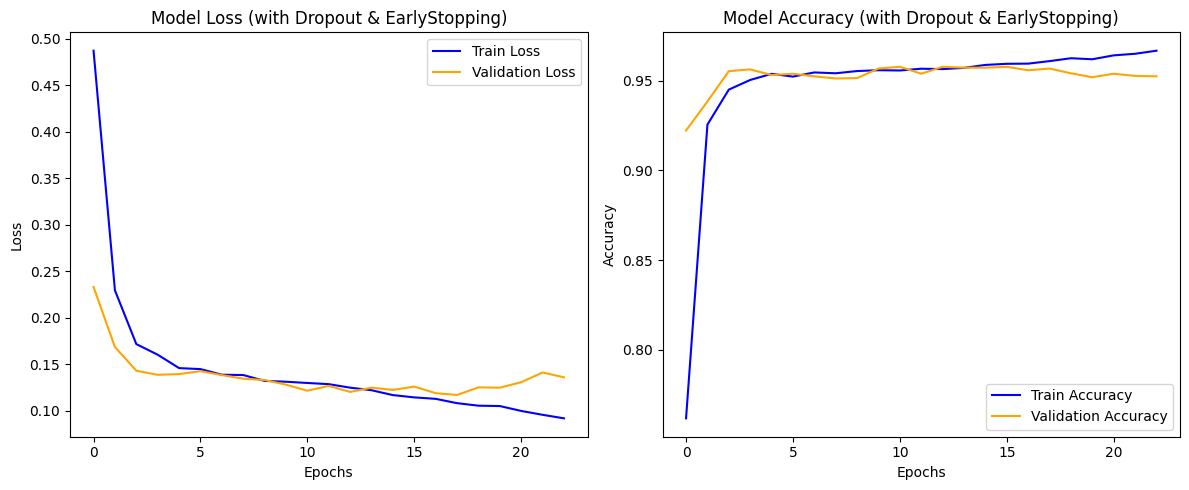

In [40]:
# 2. Plotting the Learning Curves
plt.figure(figsize=(12, 5))

# Plot Model Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Model Loss (with Dropout & EarlyStopping)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot Model Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Model Accuracy (with Dropout & EarlyStopping)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

Prediction on Test Data

Evaluating Optimized Model on Test Data:
Final Test Loss: 0.1159
Final Test Accuracy: 95.79%
Final Test AUC: 0.9908

Generating Predictions...
130/130 ━━━━━━━━━━━━━━━━━━━━ 17s 132ms/step

Classification Report:
              precision    recall  f1-score   support

 Parasitized       0.97      0.94      0.96      2068
  Uninfected       0.94      0.97      0.96      2068

    accuracy                           0.96      4136
   macro avg       0.96      0.96      0.96      4136
weighted avg       0.96      0.96      0.96      4136



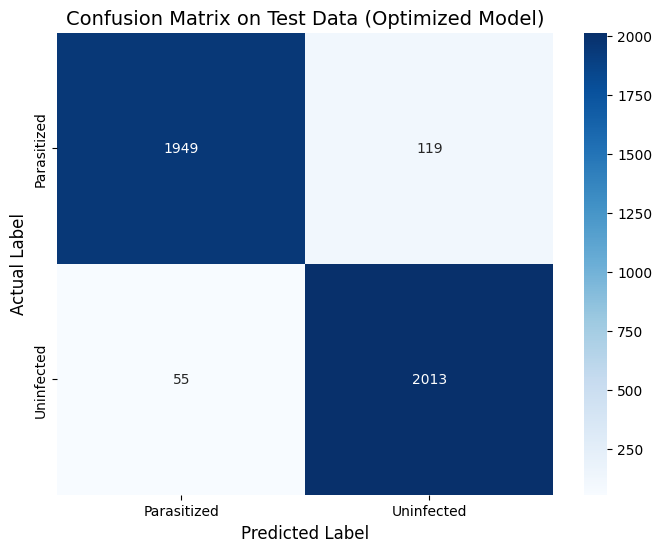

In [41]:
# 1. Evaluate on Test Data
print("Evaluating Optimized Model on Test Data:")
# Now evaluate returns 3 values (Loss, Accuracy, AUC)
test_loss, test_accuracy, test_auc = model.evaluate(test_data, verbose=0)
print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Final Test AUC: {test_auc:.4f}")

# 2. Get Predictions for Confusion Matrix & Report
print("\nGenerating Predictions...")
test_data.reset() 
y_pred_probs = model.predict(test_data)
y_pred_classes = (y_pred_probs > 0.5).astype(int).flatten()
y_true = test_data.classes
class_names = list(test_data.class_indices.keys())

# 3. Print Classification Report (Professional Metrics)
print("\nClassification Report:")
print(classification_report(y_true, y_pred_classes, target_names=class_names))

# 4. Create Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.title('Confusion Matrix on Test Data (Optimized Model)', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.show()

Analyzing Misclassified Images...
Total misclassified images: 174


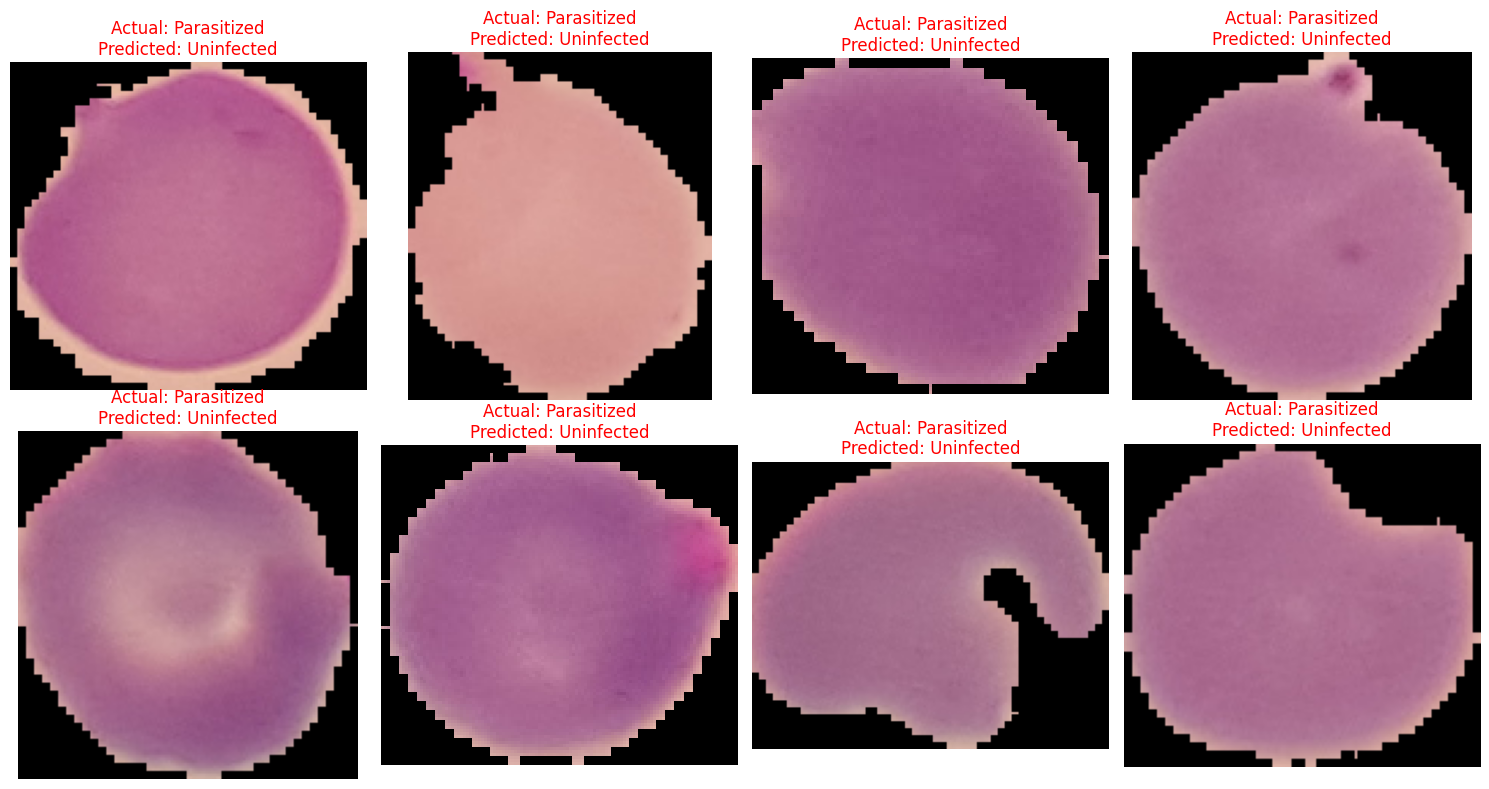

In [43]:
print("Analyzing Misclassified Images...")

# 1. Find indices where predictions don't match true labels
misclassified_indices = np.where(y_pred_classes != y_true)[0]
print(f"Total misclassified images: {len(misclassified_indices)}")

# 2. Display a sample of misclassified images (up to 8 images)
num_images_to_show = min(8, len(misclassified_indices))

if num_images_to_show > 0:
    plt.figure(figsize=(15, 8))
    
    for i in range(num_images_to_show):
        # Get the index of the misclassified image
        idx = misclassified_indices[i]
        
        # Retrieve the actual file path of this image from the generator
        img_path = test_data.filepaths[idx]
        
        # Read the original image
        img = mpimg.imread(img_path)
        
        # Get True and Predicted label names
        true_label_name = class_names[y_true[idx]]
        pred_label_name = class_names[y_pred_classes[idx]]
        
        # Plot the image
        plt.subplot(2, 4, i+1)
        plt.imshow(img)
        # Red title to indicate it's an error
        plt.title(f"Actual: {true_label_name}\nPredicted: {pred_label_name}", color='red')
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("The model made no mistakes on this batch.")

Save Model

In [42]:
model.save('malaria_cnn_model.keras')  
print("Model saved successfully as 'malaria_cnn_model.keras'")

Model saved successfully as 'malaria_cnn_model.keras'
